In [188]:
import os
import pandas as pd
import matplotlib.pylab as plt
from Data_Analyse_Vraag import Demand
from Data_Analyse_Aanbod import Offer


import time
from itertools import cycle
import pandas as pd

import numpy as np
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
import pyomo.environ as pyo
from pyomo.contrib.appsi.solvers.highs import Highs



import matplotlib.pyplot as plt
import numpy as np

# current_path = os.getcwd()
# print(current_path)

In [90]:
demand = Demand()

unique_locations = demand.unique_locations
unique_bikes = demand.unique_bikes

print(unique_locations)
print(unique_bikes)

['50/50 Leger des Heils', 'Aachen', 'Aalborg', 'Aarhus', 'Amsterdam', 'Antwerp', 'Arnhem', 'Barcelona', 'Barneveld (distributie)', 'Berlin', 'Bike Repair Shop Sittard', 'Bonn', 'Braunschweig', 'Breda', 'Bremen', 'Brussel', 'Cologne', 'Copenhagen', 'Delft', 'Den Bosch', 'Den Haag', 'Dresden', 'Düsseldorf', 'Ede - Wageningen', 'Eindhoven', 'Enschede', 'Frankfurt', 'Freiburg', 'Gent', 'Göttingen', 'Groningen', 'Haarlem', 'Halle', 'Hamburg', 'Hannover', 'Heidelberg', 'Karlsruhe', 'Kiel', 'Leeuwarden', 'Leiden', 'Leipzig', 'Leuven', 'London', 'Lübeck', 'Lyon', 'Maastricht', 'Mainz-Wiesbaden', 'Mechelen', 'Milan', 'Munich', 'Münster', 'Nantes', 'Nijmegen', 'Odense', 'Oldenburg', 'Osnabrück', 'Paris', 'PI', 'Potsdam', 'Regional Warehouse Belgium', 'Regional Warehouse Den Bosch - Eindhoven', 'Regional Warehouse Den Hoorn', 'Regional Warehouse Groningen', 'Regional Warehouse Tilburg - Breda', 'Regional Warehouse Wijchen', 'Rotterdam', 'Smart Velo Mobility', 'Strasbourg', 'Stuttgart', 'Tilburg',

In [91]:
offer = Offer()
offer.offer_per_location('Amsterdam')
# demand.demand_per_location('Amsterdam')

,Geographical Indicator,Colour Category,'23-01,'23-02,'23-03,'23-04,'23-05,'23-06,'23-07,'23-08,...,'24-12,'25-01,'25-02,'25-03,'25-04,'25-05,'25-06,'25-07,'25-08,'25-09
28,Amsterdam,Deluxe 7,11.0,1.0,1.0,3.0,1.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,Amsterdam,Original 1,7.0,7.0,6.0,6.0,6.0,6.0,7.0,6.0,...,6.0,4.0,4.0,5.0,5.0,8.0,4.0,3.0,3.0,0.0
30,Amsterdam,Original 1+,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31,Amsterdam,Power 1,6.0,6.0,1.0,3.0,3.0,76.0,102.0,64.0,...,11.0,2.0,1.0,1.0,25.0,3.0,1.0,1.0,1.0,0.0
32,Amsterdam,Power 7,59.0,56.0,56.0,48.0,159.0,139.0,241.0,146.0,...,43.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
33,Amsterdam,Power Plus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34,Amsterdam,Totaal,83.0,70.0,64.0,60.0,169.0,222.0,351.0,217.0,...,64.0,6.0,5.0,6.0,30.0,11.0,5.0,4.0,4.0,0.0


## Voorbeeld

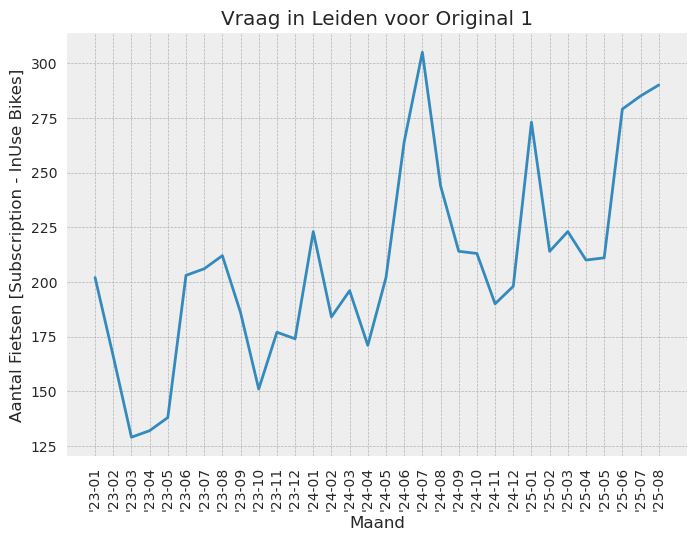

In [92]:
location = 'Leiden'
bike_type = unique_bikes[-1]

# Voor vraag
demand.plot_demand_per_location_and_bike_type(location, bike_type)

In [93]:
demand_leiden = demand.return_dict_info(location, bike_type)
demand_leiden

{"'23-01": 202.0,
 "'23-02": 166.0,
 "'23-03": 129.0,
 "'23-04": 132.0,
 "'23-05": 138.0,
 "'23-06": 203.0,
 "'23-07": 206.0,
 "'23-08": 212.0,
 "'23-09": 186.0,
 "'23-10": 151.0,
 "'23-11": 177.0,
 "'23-12": 174.0,
 "'24-01": 223.0,
 "'24-02": 184.0,
 "'24-03": 196.0,
 "'24-04": 171.0,
 "'24-05": 202.0,
 "'24-06": 264.0,
 "'24-07": 305.0,
 "'24-08": 244.0,
 "'24-09": 214.0,
 "'24-10": 213.0,
 "'24-11": 190.0,
 "'24-12": 198.0,
 "'25-01": 273.0,
 "'25-02": 214.0,
 "'25-03": 223.0,
 "'25-04": 210.0,
 "'25-05": 211.0,
 "'25-06": 279.0,
 "'25-07": 285.0,
 "'25-08": 290.0,
 "'25-09": 0.0}

## Opdracht

In [171]:
winkels_coordinaten = {
    "Rotterdam": (51.9225, 4.479167),
    "Leiden": (52.158333, 4.493056),
    "Den Haag": (52.0705, 4.3007),
    "Delft": (52.006667, 4.355556),
    "Breda": (51.5888, 4.7760),
    "Utrecht": (52.0907, 5.1214),
    "Amsterdam": (52.3676, 4.9541),
}

distributie_coordinaten = {
    "Haarlem WH": (52.3874, 4.6462),
    "Den Hoorn WH": (52.0033, 4.3181),
    "Utrecht WH": (52.0907, 5.1214),
    "Amsterdam WH": (52.3676, 4.9041),
}

In [320]:
bike_type = unique_bikes[5]
depot = "Haarlem WH"
index = 10 # voor maand

winkels = list(winkels_coordinaten.keys())
coordinaten_winkels = np.array(list(winkels_coordinaten.values()))
depot_coordinaten = np.array([distributie_coordinaten[depot]])
print(unique_bikes)

['Deluxe 7', 'Original 1+', 'Power 1', 'Power 7', 'Power Plus', 'Original 1']


In [321]:
# bepalen van vraag voor alle winkels
demand_0 = demand.return_dict_info(winkels[0], bike_type)

def dict_to_df(input_dict, winkel_locatie):
    df = pd.DataFrame({winkel_locatie: list(input_dict.values())},
                      index = input_dict.keys())
    return df

demand_df = dict_to_df(demand_0, winkels[0])

for winkel in range(1, len(winkels)):
    demand_i = demand.return_dict_info(winkels[winkel], bike_type)
    sub_df = dict_to_df(demand_i, winkels[winkel])
    demand_df = pd.concat([demand_df, sub_df], axis=1)

In [322]:
demand_df.head()

,Rotterdam,Leiden,Den Haag,Delft,Breda,Utrecht,Amsterdam
'23-01,571.0,202.0,485.0,92.0,231.0,517.0,2162.0
'23-02,471.0,166.0,350.0,64.0,149.0,380.0,1671.0
'23-03,400.0,129.0,346.0,20.0,125.0,286.0,1579.0
'23-04,328.0,132.0,285.0,23.0,114.0,257.0,1405.0
'23-05,305.0,138.0,296.0,27.0,118.0,273.0,1443.0


In [323]:
alle_coordinaten = np.concatenate((depot_coordinaten, coordinaten_winkels), axis=0)
demands = [0] + list(demand_df.iloc[index])
capacity = 1500
n_vehicles = 4
distances = squareform(pdist(alle_coordinaten, metric="euclidean"))
distances = np.round(distances, decimals=4)  # avoid numerical errors

In [324]:
demands

[0, 264.0, 177.0, 296.0, 79.0, 82.0, 305.0, 1493.0]

### Model

In [325]:
model = pyo.ConcreteModel()

In [326]:
model.V = pyo.Set(initialize=range(len(demands)))
model.A = pyo.Set(initialize=[(i, j) for i in model.V for j in model.V if i != j])
model.K = pyo.Set(initialize=range(n_vehicles))

In [327]:
model.Q = pyo.Param(initialize=capacity)
model.q = pyo.Param(model.V, initialize={i: d for (i, d) in enumerate(demands)})
model.c = pyo.Param(model.A, initialize={(i, j): distances[i, j] for (i, j) in model.A})

In [328]:
model.x = pyo.Var(model.A, model.K, within=pyo.Binary)
model.y = pyo.Var(model.V, model.K, within=pyo.Binary)

In [329]:
# objective function
model.obj = pyo.Objective(
    expr=sum(
        model.x[i, j, k] * model.c[i, j]
        for (i, j) in model.A
        for k in model.K
    ),
    sense=pyo.minimize,
)

In [330]:
# C3
def vehicle_assignment(model, i, k):
    return sum(model.x[:, i, k]) == model.y[i, k]

# C3
def comp_vehicle_assignment(model, i, k):
    return sum(model.x[i, :, k]) == model.y[i, k]

# C4 
def capacity_constraint(model, k):
    return sum(model.y[i, k] * model.q[i] for i in model.V) <= model.Q
    
# C5
def arcs_in(model, i):
    if i == model.V.first():
        return sum(model.x[:, i, :]) == len(model.K)
    else:
        return sum(model.x[:, i, :]) == 1.0

# C5
def arcs_out(model, i):
    if i == model.V.first():
        return sum(model.x[i, :, :]) == len(model.K)
    else:
        return sum(model.x[i, :, :]) == 1.0

# C6
def subtour_elimination(model, S, Sout, h, k):
    nodes_out = sum(model.x[i, j, k] for i in S for j in Sout)
    return model.y[h, k] <= nodes_out


In [331]:
model.vehicle_assignment = pyo.Constraint(model.V, model.K, rule=vehicle_assignment) # C3
model.comp_vehicle_assignment = pyo.Constraint(model.V, model.K, rule=comp_vehicle_assignment) # C3
model.capacity_constraint = pyo.Constraint(model.K, rule=capacity_constraint) # C4
# model.arcs_in = pyo.Constraint(model.V, rule=arcs_in) # C5
# model.arcs_out = pyo.Constraint(model.V, rule=arcs_out) # C5
model.subtour_elimination = pyo.ConstraintList() # C6

In [332]:
def find_arcs(model):
    arcs = []
    for i, j in model.A:
        for k in model.K:
            if np.isclose(model.x[i, j, k].value, 1):
                arcs.append((i, j))
    return arcs


def find_subtours(arcs):
    G = nx.DiGraph(arcs)
    subtours = list(nx.strongly_connected_components(G))
    return subtours

In [333]:
def eliminate_subtours(model, subtours):
    proceed = False
    for S in subtours:
        if 0 not in S:
            proceed = True
            Sout = {i for i in model.V if i not in S}
            for h in S:
                for k in model.K:
                    model.subtour_elimination.add(
                      subtour_elimination(model, S, Sout, h, k)
                    )
    return proceed

In [334]:
def solve_step(model, solver):
    sol = solver.solve(model)
    arcs = find_arcs(model)
    subtours = find_subtours(arcs)
    time.sleep(0.1)
    proceed = eliminate_subtours(model, subtours)
    return sol, proceed 


def solve(model, solver):
    proceed = True
    while proceed:
        sol, proceed = solve_step(model, solver)
    return sol

In [335]:
# from pyomo.__future__ import solver_factory
solver = Highs()
# solver = solver_factory("appsi_highs")
# solver = pyo.SolverFactory("appsi_highs").solve(model, tee=False)  # or "appsi_highs"
solver.highs_options = {
    "log_file": "Highs.log",
    "mip_heuristic_effort": 0.2,
    "mip_detect_symmetry": True,
    "mip_rel_gap": 1e-6,
}

solution = solve(model, solver)

In [336]:
def find_tours(model):
    tours = []
    for k in model.K:
        node = 0
        tours.append([0])
        while True:
            for j in model.V:
                if (node, j) in model.A:
                    if np.isclose(model.x[node, j, k].value, 1):
                        node = j
                        tours[-1].append(node)
                        break
            if node == 0:
                break
    return tours

In [337]:
solution.best_feasible_objective

0.0

In [338]:
tours = find_tours(model)
print(tours)

[[0], [0], [0], [0]]


In [339]:
print(coordinaten)
x, y = coordinaten[:, 0], coordinaten[:, 1] 

[[51.9225    4.479167]
 [52.158333  4.493056]
 [52.0705    4.3007  ]
 [52.006667  4.355556]
 [51.5888    4.776   ]
 [52.0907    5.1214  ]
 [52.3676    4.9541  ]]


IndexError: index 7 is out of bounds for axis 0 with size 7

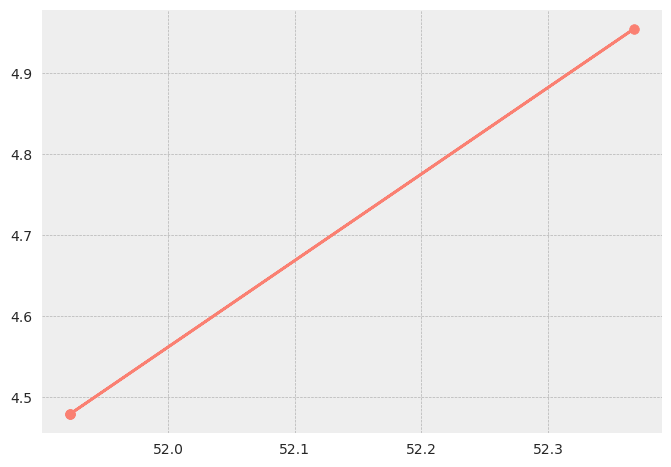

In [286]:
colours = [
    "darkslategray",
    "crimson",
    "salmon",
    "saddlebrown",
    "peru",
    "darkorange",
    "goldenrod",
    "khaki",
    "olivedrab",
    "mediumseagreen",
    "forestgreen",
    "teal",
    "cadetblue",
    "skyblue",
    "steelblue",
    "navy",
    "slateblue",
    "mediumpurple",
    "orchid",
    "palevioletred",
]

colours = colours[2:15]

for tour in range(len(tours)):
    tour_coordinates = coordinaten[tours[tour]]
    x0, y0 = tour_coordinates[:, 0], tour_coordinates[:, 1]
    plt.scatter(x0, y0, color=colours[tour], zorder=2)
    plt.plot(x0, y0, color=colours[tour], label=f'Tour {tour}', zorder=1)

plt.title(f'K={n_vehicles} geeft: {round(solution.best_feasible_objective, 3)}')
plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.legend()
plt.show() 